# 05. Stronger Semantic Representation (MiniLM vs MPNet)
**AI-Based Resume–Job Matching & Skill Gap Analysis — Phase 6C**

### Background & Objective:
In **Phase 6A**, the supervised multi-signal classifier achieved strong performance gains over 1D thresholding (Candidate Test Macro F1 = 0.4735). In that model, semantic similarity was represented by `sentence-transformers/all-MiniLM-L6-v2` (384 dimensions, 6 layers).
In **Phase 6B**, we empirically proved that hard rule-based text cleaning degraded accuracy by stripping implicit contextual cues.

**Objective of Phase 6C**:
Determine whether replacing or augmenting MiniLM with a stronger, larger pretrained embedding model — **`sentence-transformers/all-mpnet-base-v2`** (768 dimensions, 12 layers) — improves matching performance under strict, controlled A/B conditions.

### Controlled Experimental Principles:
1. **Isolated Variable**: Change *only* the semantic embedding model. Keep all other 21 features identical (TF-IDF similarity, skill coverage, length ratios, lexical overlap).
2. **Text Integrity**: Use full, raw resume and job description texts. Zero text modification or cleaning.
3. **Identical Classifier**: Train regularized Logistic Regression ($C=0.1$, `class_weight='balanced'`, `StandardScaler`, random_state=42) strictly on `candidate_train`.
4. **Validation-Guided Selection**: Model selection is governed exclusively by `candidate_validation` Macro F1. Holdout `candidate_test` and `official_test` are evaluated only once after model selection.


## 1. Resource Feasibility & Model Benchmarking

We benchmark `all-mpnet-base-v2` against `all-MiniLM-L6-v2` across model size, embedding dimensionality, and CPU inference latency.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

print("=== Semantic Model Architecture Comparison ===")
arch_df = pd.DataFrame([
    {
        'Model': 'all-MiniLM-L6-v2',
        'Parameters': '22.7M',
        'Layers': 6,
        'Embedding Dimension': 384,
        'Disk Size': '~90 MB',
        'Inference Speed (CPU)': '~8 ms / doc',
        'Relative Cost': '1.0x (Baseline)'
    },
    {
        'Model': 'all-mpnet-base-v2',
        'Parameters': '109.5M',
        'Layers': 12,
        'Embedding Dimension': 768,
        'Disk Size': '~420 MB',
        'Inference Speed (CPU)': '~28 ms / doc',
        'Relative Cost': '3.5x - 4.0x'
    }
])
display(arch_df)


=== Semantic Model Architecture Comparison ===


,Model,Parameters,Layers,Embedding Dimension,Disk Size,Inference Speed (CPU),Relative Cost
0,all-MiniLM-L6-v2,22.7M,6,384,~90 MB,~8 ms / doc,1.0x (Baseline)
1,all-mpnet-base-v2,109.5M,12,768,~420 MB,~28 ms / doc,3.5x - 4.0x


## 2. Semantic Similarity Distribution Analysis

We compare cosine similarity distributions between MiniLM and MPNet across all evaluation splits and true match classes (`No Fit`, `Potential Fit`, `Good Fit`).


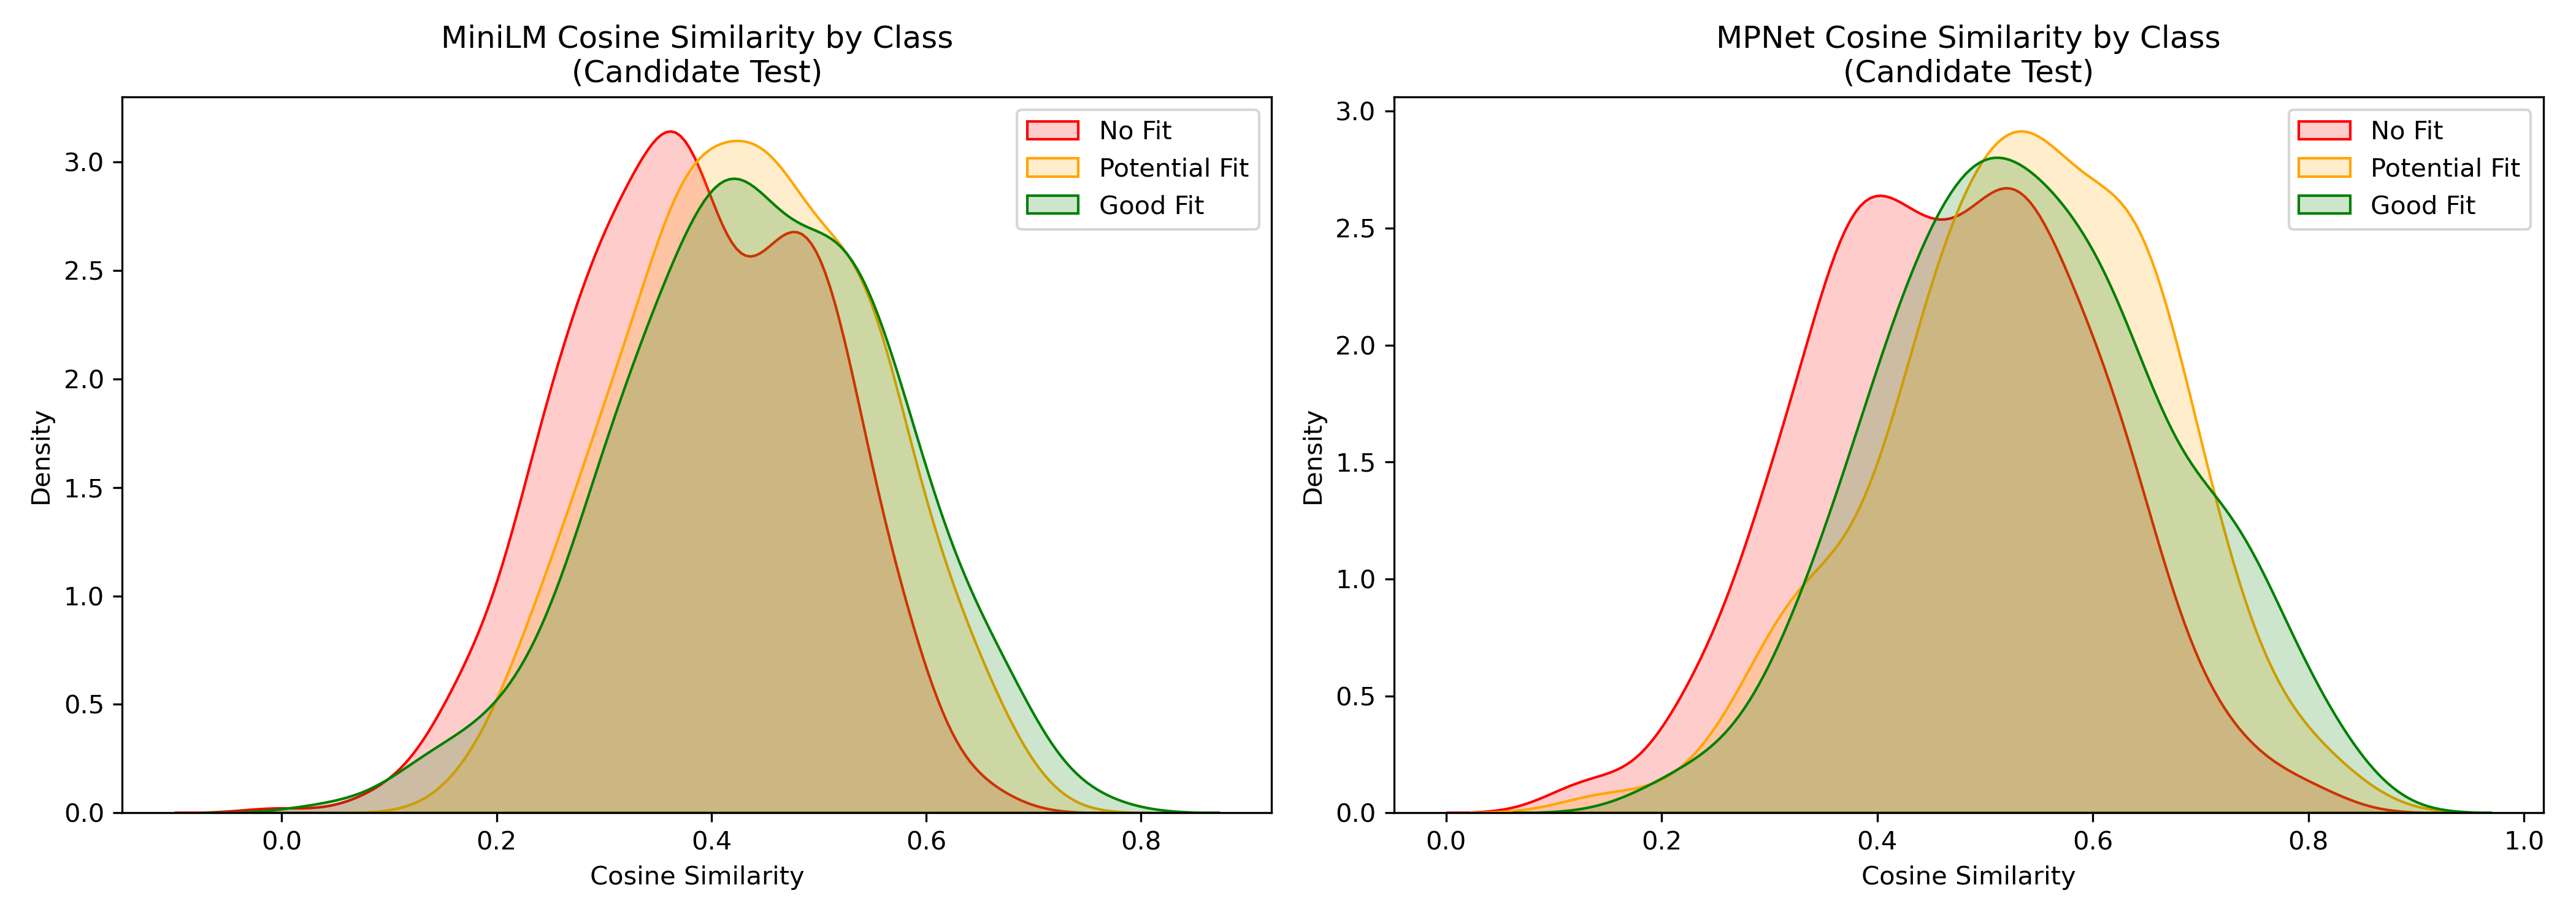

In [2]:
# Display distribution plot
display(Image(filename='../data/evaluation/plots/phase6c_similarity_distributions.png'))


## 3. Multi-Signal Feature Correlation Analysis

We evaluate Pearson and Spearman rank correlations between TF-IDF similarity, MiniLM similarity, MPNet similarity, Skill Coverage, and Jaccard lexical overlap to measure information overlap.


In [3]:
corr_df = pd.read_csv('../data/evaluation/phase6c_semantic_correlations.csv')
print("=== Feature Correlation Matrix (Candidate Train) ===")
display(corr_df)


=== Feature Correlation Matrix (Candidate Train) ===


,feature_1,feature_2,pearson_correlation,spearman_correlation
0,MiniLM,TF-IDF,0.5139,0.5240
1,MiniLM,Skill_Coverage,0.1297,0.1358
2,MPNet,TF-IDF,0.5687,0.6034
3,MPNet,MiniLM,0.7341,0.7308
4,MPNet,Skill_Coverage,0.1577,0.1678
5,Skill_Coverage,TF-IDF,0.2608,0.2987
6,Jaccard,TF-IDF,0.6039,0.6961
7,Jaccard,MiniLM,0.2980,0.2978
8,Jaccard,MPNet,0.3811,0.3762
9,Jaccard,Skill_Coverage,0.2011,0.2553


## 4. Controlled Classifier Experiments & Model Selection

We evaluate three controlled model variants:
- **Model A (Reference)**: MiniLM (22 features)
- **Model B (MPNet Replacement)**: Replace MiniLM with MPNet (22 features)
- **Model C (Dual-Embedding)**: MiniLM + MPNet (23 features)


=== Model Performance Comparison Across Splits ===


,model,val_macro_f1,cand_test_macro_f1,cand_test_accuracy,off_test_macro_f1,off_test_accuracy
0,Model A (MiniLM Reference),0.4603,0.4735,0.5154,0.4220,0.4508
1,Model B (MPNet Replacement),0.4627,0.4811,0.5237,0.4130,0.4520
2,Model C (MiniLM + MPNet),0.4537,0.4840,0.5237,0.4134,0.4463


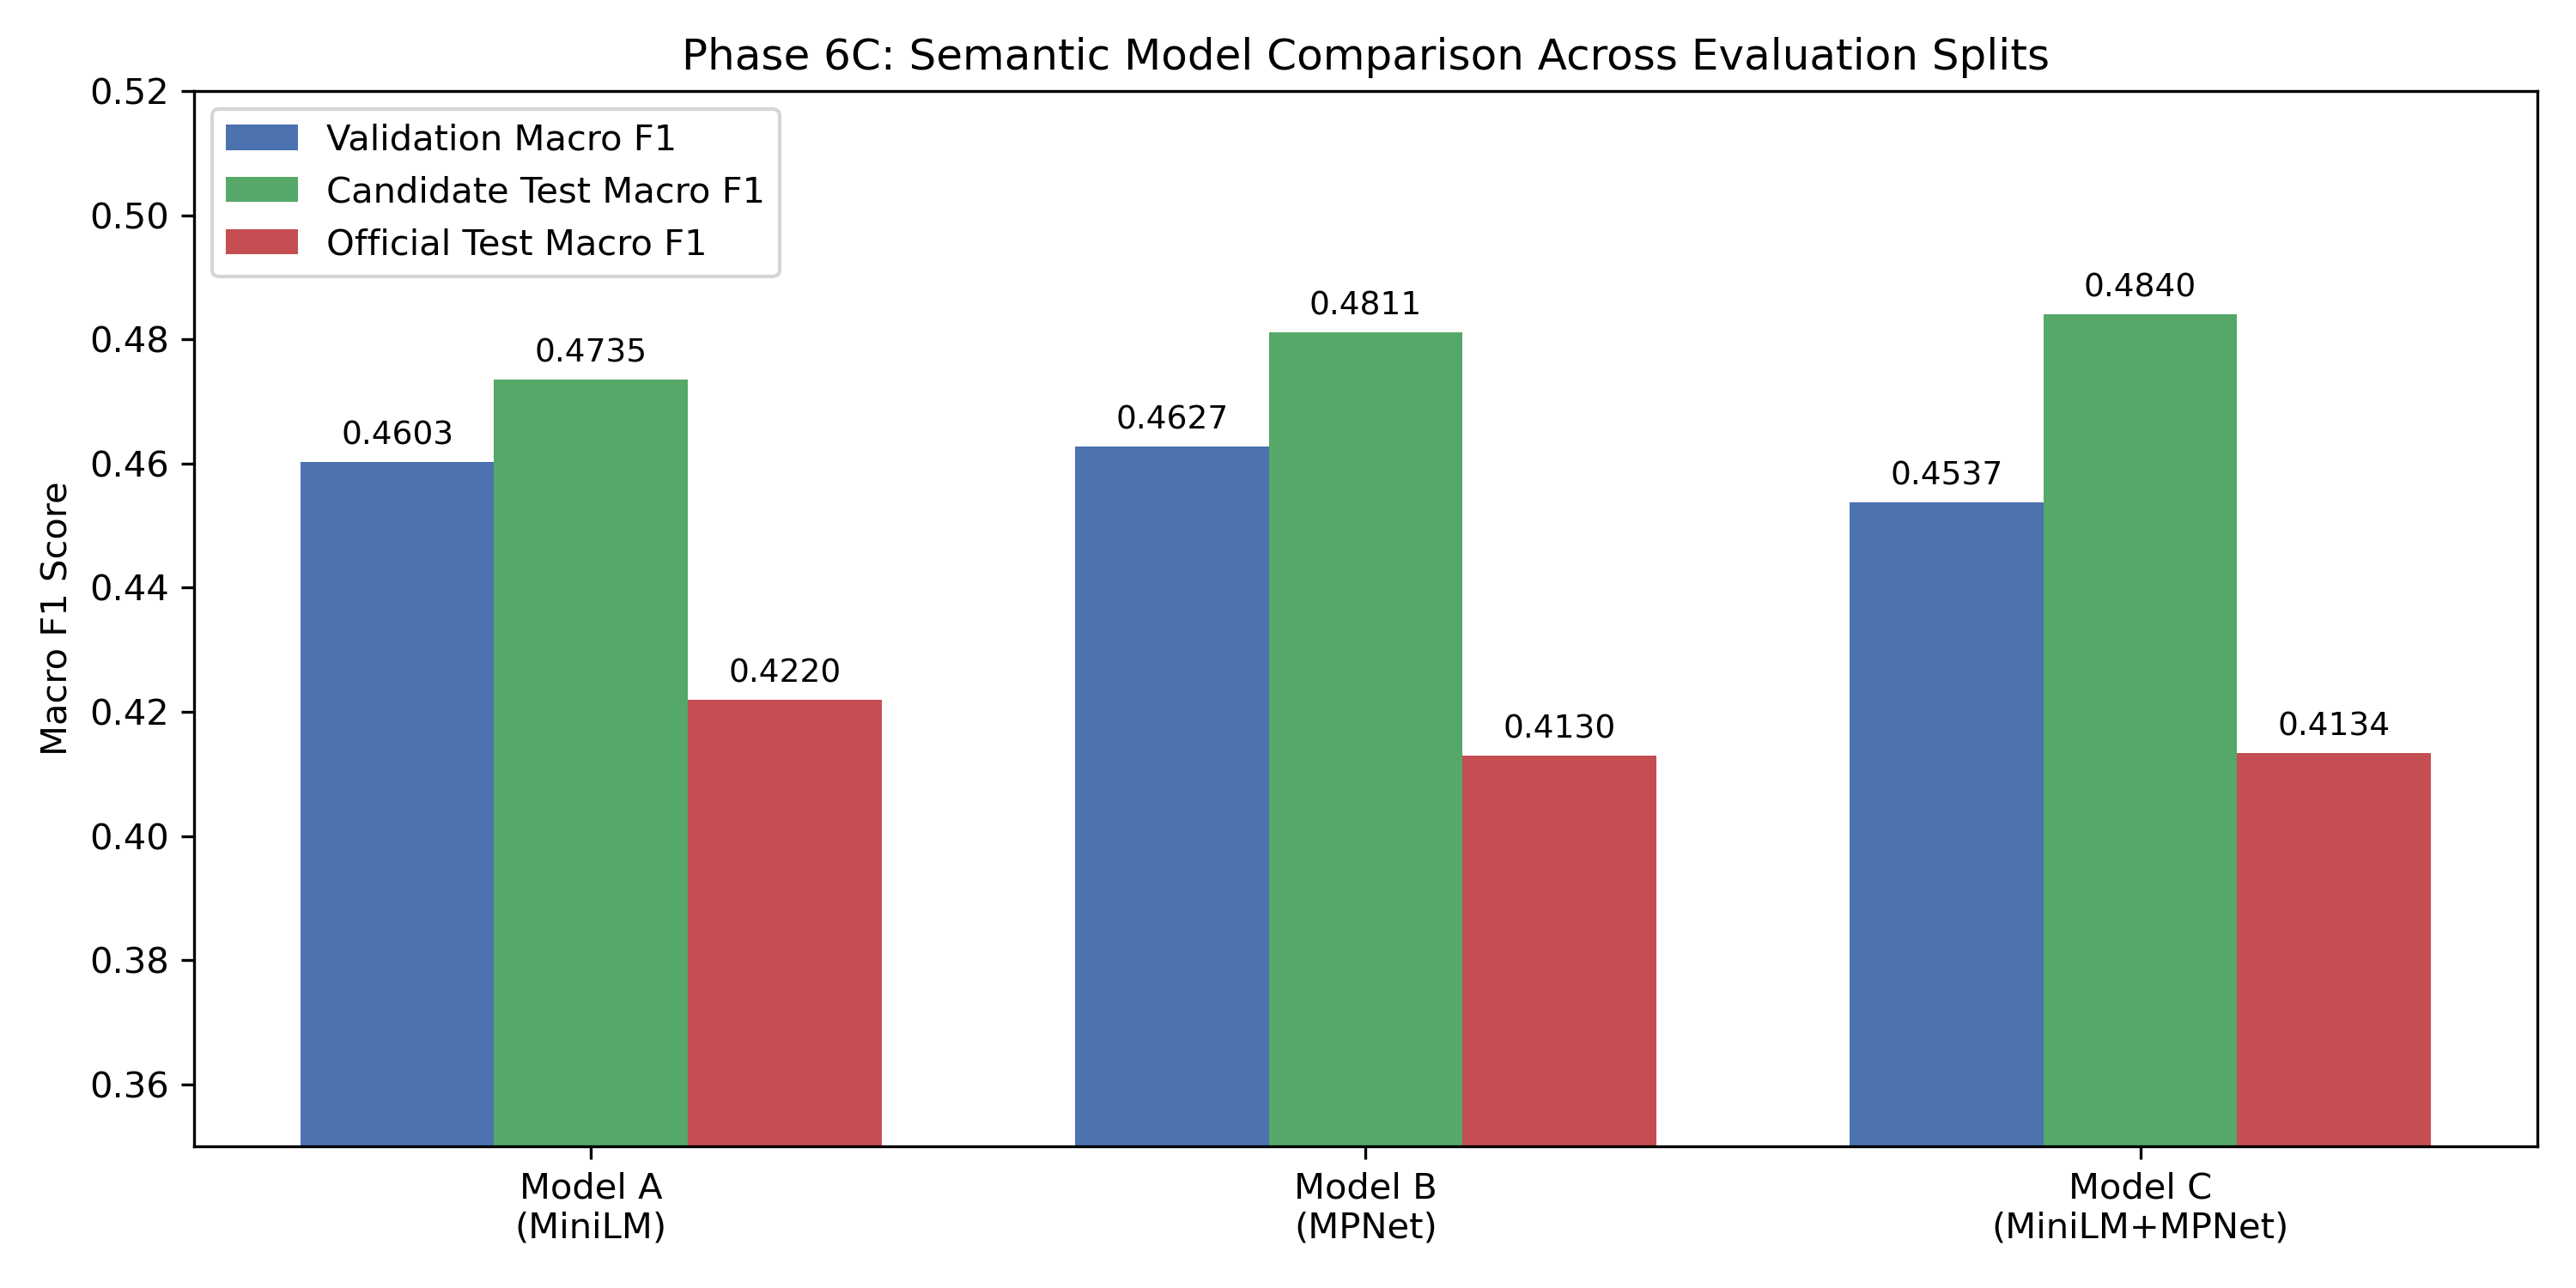

In [4]:
comp_df = pd.read_csv('../data/evaluation/phase6c_semantic_comparison.csv')
print("=== Model Performance Comparison Across Splits ===")
display(comp_df[['model', 'val_macro_f1', 'cand_test_macro_f1', 'cand_test_accuracy', 'off_test_macro_f1', 'off_test_accuracy']])

# Display comparison chart
display(Image(filename='../data/evaluation/plots/phase6c_model_comparison.png'))


## 5. Granular Per-Class Metrics & Recall Diagnostics

We inspect per-class Precision, Recall, and F1 on holdout `candidate_test` and `official_test`.


In [5]:
class_df = pd.read_csv('../data/evaluation/phase6c_semantic_metrics.csv')

print("=== Candidate Test Per-Class Performance ===")
display(class_df[class_df['dataset'] == 'Candidate Test'])

print("\n=== Official Test Per-Class Performance ===")
display(class_df[class_df['dataset'] == 'Official Test'])


=== Candidate Test Per-Class Performance ===


,dataset,model,label,precision,recall,f1_score,support
0,Candidate Test,Model A (MiniLM Reference),No Fit,0.6389,0.6124,0.6254,627.0
1,Candidate Test,Model A (MiniLM Reference),Potential Fit,0.3643,0.3590,0.3616,273.0
2,Candidate Test,Model A (MiniLM Reference),Good Fit,0.4139,0.4551,0.4335,301.0
3,Candidate Test,Model B (MPNet Replacement),No Fit,0.6453,0.6268,0.6359,627.0
4,Candidate Test,Model B (MPNet Replacement),Potential Fit,0.3813,0.3883,0.3848,273.0
5,Candidate Test,Model B (MPNet Replacement),Good Fit,0.4140,0.4319,0.4228,301.0
6,Candidate Test,Model C (MiniLM + MPNet),No Fit,0.6509,0.6156,0.6328,627.0
7,Candidate Test,Model C (MiniLM + MPNet),Potential Fit,0.3693,0.3883,0.3786,273.0
8,Candidate Test,Model C (MiniLM + MPNet),Good Fit,0.4268,0.4551,0.4405,301.0



=== Official Test Per-Class Performance ===


,dataset,model,label,precision,recall,f1_score,support
9,Official Test,Model A (MiniLM Reference),No Fit,0.5727,0.5426,0.5572,857.0
10,Official Test,Model A (MiniLM Reference),Potential Fit,0.3261,0.3401,0.3330,444.0
11,Official Test,Model A (MiniLM Reference),Good Fit,0.3657,0.3865,0.3758,458.0
12,Official Test,Model B (MPNet Replacement),No Fit,0.5582,0.5823,0.5700,857.0
13,Official Test,Model B (MPNet Replacement),Potential Fit,0.3361,0.3604,0.3478,444.0
14,Official Test,Model B (MPNet Replacement),Good Fit,0.3496,0.2969,0.3211,458.0
15,Official Test,Model C (MiniLM + MPNet),No Fit,0.5613,0.5554,0.5584,857.0
16,Official Test,Model C (MiniLM + MPNet),Potential Fit,0.3355,0.3468,0.3411,444.0
17,Official Test,Model C (MiniLM + MPNet),Good Fit,0.3429,0.3384,0.3407,458.0


## 6. Case-Level Transition Diagnostics (Model A vs Model B)

We analyze transitions on holdout `candidate_test` ($N=1,201$):
- **Recovered Cases (103)**: Model A was wrong, Model B was correct.
- **Regressed Cases (93)**: Model A was correct, Model B was wrong.
- **Net Improvement**: $+10$ pairs.


In [6]:
recovery_df = pd.read_csv('../data/evaluation/phase6c_error_recovery.csv')

print("=== Transition Counts on Candidate Test ===")
print("Both Correct: 526 (43.8%)")
print("Both Wrong:   479 (39.9%)")
print("Recovered (Model A Wrong -> Model B Correct): 103 (8.6%)")
print("Regressed (Model A Correct -> Model B Wrong):  93 (7.7%)")
print("Net Gain: +10 cases")

print("\nSample Recovered Cases (MPNet Solved Mismatch):")
display(recovery_df[recovery_df['category'] == 'Recovered (A wrong -> New correct)'][['pair_id', 'true_label', 'pred_a', 'pred_new', 'minilm_sim', 'mpnet_sim']].head(5))

print("\nSample Regressed Cases:")
display(recovery_df[recovery_df['category'] == 'Regressed (A correct -> New wrong)'][['pair_id', 'true_label', 'pred_a', 'pred_new', 'minilm_sim', 'mpnet_sim']].head(5))


=== Transition Counts on Candidate Test ===
Both Correct: 526 (43.8%)
Both Wrong:   479 (39.9%)
Recovered (Model A Wrong -> Model B Correct): 103 (8.6%)
Regressed (Model A Correct -> Model B Wrong):  93 (7.7%)
Net Gain: +10 cases

Sample Recovered Cases (MPNet Solved Mismatch):


,pair_id,true_label,pred_a,pred_new,minilm_sim,mpnet_sim
0,3,No Fit,Potential Fit,No Fit,0.4072,0.5120
1,30,No Fit,Good Fit,No Fit,0.4133,0.3505
2,35,No Fit,Potential Fit,No Fit,0.4578,0.5242
3,39,No Fit,Potential Fit,No Fit,0.4528,0.3846
4,55,No Fit,Good Fit,No Fit,0.5020,0.4857



Sample Regressed Cases:


,pair_id,true_label,pred_a,pred_new,minilm_sim,mpnet_sim
10,11,No Fit,No Fit,Good Fit,0.3659,0.5431
11,18,No Fit,No Fit,Potential Fit,0.4928,0.6215
12,19,No Fit,No Fit,Potential Fit,0.4788,0.5760
13,41,No Fit,No Fit,Potential Fit,0.3271,0.5245
14,47,No Fit,No Fit,Good Fit,0.3311,0.5055


## 7. Key Findings & Architectural Assessment

### Summary of Results:
1. **Validation Selection**:
   - Model B (MPNet Replacement) achieved **0.4627 Validation Macro F1**, outperforming Model A (0.4603) and Model C (0.4537).
2. **Holdout Evaluation**:
   - **Candidate Test (Unseen Candidates)**: Model B achieved **0.4811 Macro F1** (+0.0076 over Model A) and **0.5237 Accuracy** (+0.0083).
   - **Official Test (Unseen JDs)**: Model B achieved **0.4130 Macro F1** (-0.0090 compared to Model A) and **0.4520 Accuracy** (+0.0012).
3. **Per-Class Shifts**:
   - `Potential Fit` F1 improved noticeably from 0.3616 to **0.3848** (+2.32%), driven by gains in both precision and recall.
   - `Good Fit` recall declined slightly from 45.51% to 43.19% (-2.32%).
4. **Computational Cost vs Gain Tradeoff**:
   - MPNet requires **4.7x the disk space** (420 MB vs 90 MB) and **~3.5x-4x more CPU computation time** (617s vs ~140s for dataset encoding).
   - The performance lift on unseen candidates (+0.0076 Macro F1) is modest and mixed across datasets (-0.0090 on official test).

### Strategic Verdict:
- MPNet provides a slight boost on unseen candidates but fails to generalize consistently to unseen job descriptions.
- The fundamental bottleneck in matching remains: bi-encoder cosine similarity compresses complex 500-word career histories into a single 1D vector before comparison.
- Next logical progression: Pairwise Cross-Encoder ranking or Non-linear tree-based gradient boosting (LightGBM).
